In [6]:
!pip install rdkit
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score, roc_auc_score, confusion_matrix,roc_curve,ConfusionMatrixDisplay

In [7]:
df=pd.read_csv("/Users/m.saikarthikeya/Desktop/XGBioactiveNew/notebooks/CHEMBL230_Preprocessed_Data_V2.csv")
print(df)

     Molecule ChEMBL ID                                             Smiles  \
0           CHEMBL70104    CC1(C)OC(=O)C(OC2CCCCC2)=C1c1ccc(S(C)(=O)=O)cc1   
1           CHEMBL96098     CCc1ccc(-c2ncc(Cl)cc2-c2ccc(S(C)(=O)=O)cc2)cn1   
2           CHEMBL97179  CCCCOC(=O)Cc1c(C)n(C(=O)c2ccc(Cl)cc2)c2ccc(OC)...   
3               CHEMBL6     COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1   
4          CHEMBL355781  CS(=O)(=O)c1ccc(-c2csc(CC(=O)O)c2-c2ccc(F)cc2)cc1   
...                 ...                                                ...   
6834          CHEMBL118  Cc1ccc(-c2cc(C(F)(F)F)nn2-c2ccc(S(N)(=O)=O)cc2...   
6835          CHEMBL521                         CC(C)Cc1ccc(C(C)C(=O)O)cc1   
6836          CHEMBL139                     O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl   
6837       CHEMBL121626                       Cc1c(Cl)cccc1Nc1ccccc1C(=O)O   
6838          CHEMBL571                  CC(C(=O)O)c1cccc(C(=O)c2ccccc2)c1   

     Standard Type  Standard Value Standard Units  Activity  
0

In [8]:
df = (
    df.groupby("Molecule ChEMBL ID", as_index=False)
      .agg(
          smiles=("Smiles", "first"),
          standard_value=("Standard Value", "median"),
      )
      .rename(columns={"Molecule ChEMBL ID": "molecule_chembl_id"})
)
print(df)

     molecule_chembl_id                                             smiles  \
0          CHEMBL100091  CCCCOCCOC(=O)Cc1c(C)n(C(=O)c2ccc(Cl)cc2)c2ccc(...   
1          CHEMBL100092  CCCCCCOC(=O)Cc1c(C)n(C(=O)c2ccc(Cl)cc2)c2ccc(O...   
2          CHEMBL100156              CS(=O)(=O)c1ccc(-c2cscc2-c2ccccc2)cc1   
3          CHEMBL100250              CS(=O)(=O)c1ccc(-c2ccsc2-c2ccccc2)cc1   
4          CHEMBL100331  CCCCCCCCNC(=O)Cc1c(C)n(C(=O)c2ccc(Cl)cc2)c2ccc...   
...                 ...                                                ...   
5025        CHEMBL99374           Cc1ccc(-c2cscc2-c2ccc(S(C)(=O)=O)cc2)cc1   
5026        CHEMBL99517           Cc1ccc(-c2sccc2-c2ccc(S(C)(=O)=O)cc2)cc1   
5027        CHEMBL99727  CCOC(=O)CCc1cc(-c2ccc(S(C)(=O)=O)cc2)c(-c2ccc(...   
5028        CHEMBL99828      Cc1cc(-c2ccc(S(C)(=O)=O)cc2)c(-c2ccc(F)cc2)s1   
5029        CHEMBL99933  CCCOC(=O)Cc1c(C)n(C(=O)c2ccc(Cl)cc2)c2ccc(OC)cc12   

      standard_value  
0               60.0  
1               6

In [9]:
df["target"] = (df["standard_value"] < 10000).astype(int)


In [10]:
mol_wt, log_p, tpsa, hbd, hba, rot = [], [], [], [], [], []
for smiles in df["smiles"]:
    mol = Chem.MolFromSmiles(smiles)
    mol_wt.append(Descriptors.MolWt(mol))
    log_p.append(Descriptors.MolLogP(mol))
    tpsa.append(Descriptors.TPSA(mol))
    hbd.append(Descriptors.NumHDonors(mol))
    hba.append(Descriptors.NumHAcceptors(mol))
    rot.append(Descriptors.NumRotatableBonds(mol))
df["MolWt"] = mol_wt
df["LogP"] = log_p
df["TPSA"] = tpsa
df["HBD"] = hbd
df["HBA"] = hba
df["RotatableBonds"] = rot

In [11]:
X = df[["MolWt", "LogP", "TPSA", "HBD", "HBA", "RotatableBonds"]]
y = df["target"]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
tree = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42)
jungle = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)
svm = SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42)

In [15]:
tree.fit(X_train, y_train)
jungle.fit(X_train, y_train)
svm.fit(X_train_scaled, y_train)

SVC(class_weight='balanced', probability=True, random_state=42)

In [16]:
tree_pred = tree.predict(X_test)
jungle_pred = jungle.predict(X_test)
svm_pred = svm.predict(X_test_scaled)

In [17]:
tree_prob = tree.predict_proba(X_test)[:, 1]
forest_prob = jungle.predict_proba(X_test)[:, 1]
svm_prob = svm.predict_proba(X_test_scaled)[:, 1]

In [18]:
tree_prob = tree.predict_proba(X_test)[:, 1]
jungle_prob = jungle.predict_proba(X_test)[:, 1]
svm_prob = svm.predict_proba(X_test_scaled)[:, 1]

results = pd.DataFrame({
    "Decision Tree": [accuracy_score(y_test, tree_pred), precision_score(y_test, tree_pred),
                      recall_score(y_test, tree_pred), f1_score(y_test, tree_pred),
                      roc_auc_score(y_test, tree_prob)],
    "Random Forest": [accuracy_score(y_test, jungle_pred), precision_score(y_test, jungle_pred),
                      recall_score(y_test, jungle_pred), f1_score(y_test, jungle_pred),
                      roc_auc_score(y_test, jungle_prob)],
    "SVM": [accuracy_score(y_test, svm_pred), precision_score(y_test, svm_pred),
            recall_score(y_test, svm_pred), f1_score(y_test, svm_pred),
            roc_auc_score(y_test, svm_prob)],
}, index=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])
print(results)

           Decision Tree  Random Forest       SVM
Accuracy        0.673956       0.756461  0.686879
Precision       0.751037       0.782995  0.786585
Recall          0.785818       0.892909  0.746744
F1              0.768034       0.834348  0.766147
ROC-AUC         0.654618       0.769678  0.701948


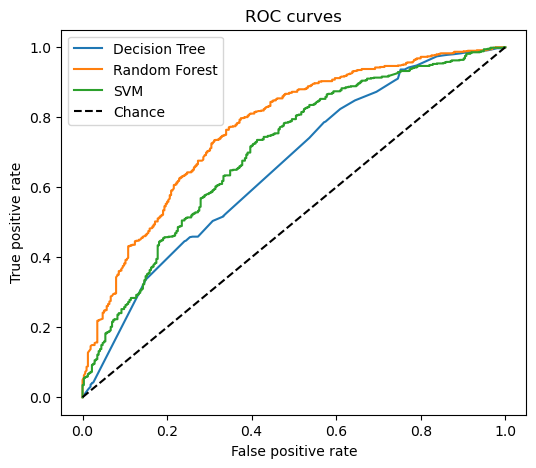

In [19]:
plt.figure(figsize=(6, 5))
for name, prob in [("Decision Tree", tree_prob), ("Random Forest", forest_prob), ("SVM", svm_prob)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend()
plt.show()

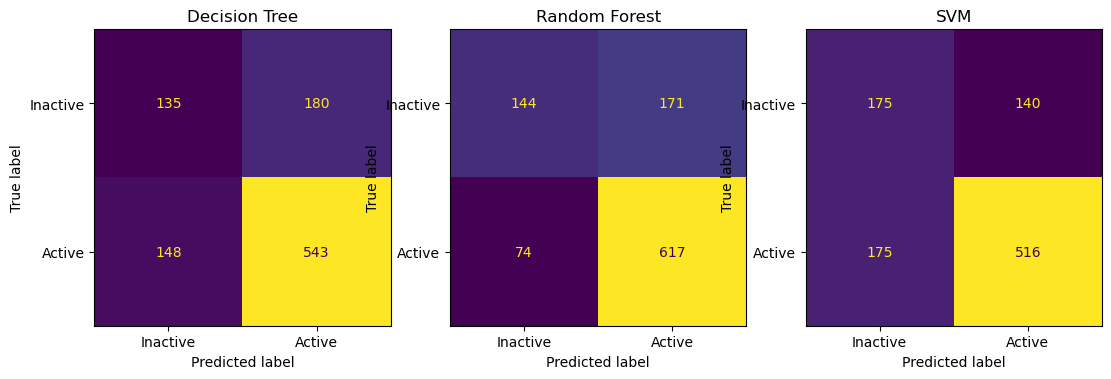

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name, pred in zip(axes, ["Decision Tree", "Random Forest", "SVM"],
                          [tree_pred, jungle_pred, svm_pred]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Inactive", "Active"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)

In [21]:
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.base import BaseEstimator, ClassifierMixin
ann = MLPClassifier(hidden_layer_sizes=(100, 50), activation='relu', max_iter=500, random_state=42)
ann.fit(X_train_scaled, y_train)
class RBFNetwork(BaseEstimator, ClassifierMixin):
    def __init__(self, n_centers=10, gamma=1.0, random_state=42):
        self.n_centers = n_centers
        self.gamma = gamma
        self.random_state = random_state
        self.kmeans = KMeans(n_clusters=self.n_centers, random_state=self.random_state, n_init=10)
        self.clf = LogisticRegression(class_weight='balanced', random_state=self.random_state)

    def _rbf_transform(self, X):
        dists = np.zeros((X.shape[0], self.n_centers))
        for i, center in enumerate(self.centers_):
            dists[:, i] = np.linalg.norm(X - center, axis=1)
        return np.exp(-self.gamma * (dists ** 2))

    def fit(self, X, y):
        self.kmeans.fit(X)
        self.centers_ = self.kmeans.cluster_centers_
        X_rbf = self._rbf_transform(X)
        self.clf.fit(X_rbf, y)
        self.classes_ = self.clf.classes_
        return self

    def predict(self, X):
        X_rbf = self._rbf_transform(X)
        return self.clf.predict(X_rbf)

    def predict_proba(self, X):
        X_rbf = self._rbf_transform(X)
        return self.clf.predict_proba(X_rbf)

rbf = RBFNetwork(n_centers=20, gamma=0.1, random_state=42)
rbf.fit(X_train_scaled, y_train)

RBFNetwork(gamma=0.1, n_centers=20)

In [22]:
ann_pred = ann.predict(X_test_scaled)
ann_prob = ann.predict_proba(X_test_scaled)[:, 1]
rbf_pred = rbf.predict(X_test_scaled)
rbf_prob = rbf.predict_proba(X_test_scaled)[:, 1]
extended_results = results.copy()
extended_results["ANN"] = [
    accuracy_score(y_test, ann_pred),
    precision_score(y_test, ann_pred),
    recall_score(y_test, ann_pred),
    f1_score(y_test, ann_pred),
    roc_auc_score(y_test, ann_prob)
]

extended_results["RBF Network"] = [
    accuracy_score(y_test, rbf_pred),
    precision_score(y_test, rbf_pred),
    recall_score(y_test, rbf_pred),
    f1_score(y_test, rbf_pred),
    roc_auc_score(y_test, rbf_prob)
]

print(extended_results)

           Decision Tree  Random Forest       SVM       ANN  RBF Network
Accuracy        0.673956       0.756461  0.686879  0.746521     0.635189
Precision       0.751037       0.782995  0.786585  0.773869     0.775510
Recall          0.785818       0.892909  0.746744  0.891462     0.659913
F1              0.768034       0.834348  0.766147  0.828514     0.713057
ROC-AUC         0.654618       0.769678  0.701948  0.727692     0.667480


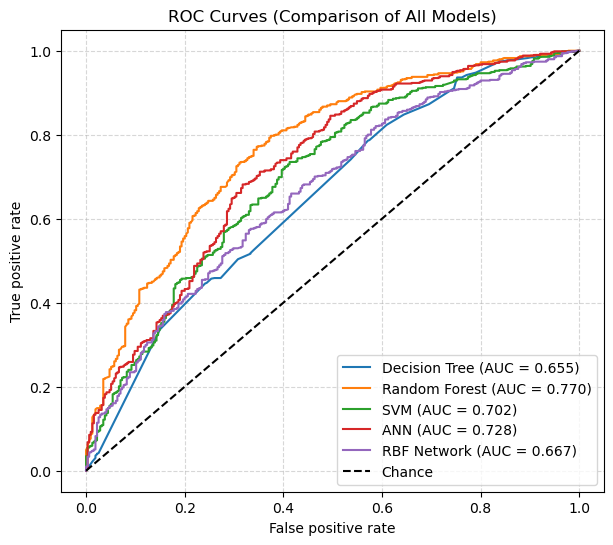

In [23]:
plt.figure(figsize=(7, 6))
models_to_plot = [
    ("Decision Tree", tree_prob),
    ("Random Forest", forest_prob),
    ("SVM", svm_prob),
    ("ANN", ann_prob),
    ("RBF Network", rbf_prob)
]

for name, prob in models_to_plot:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curves (Comparison of All Models)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

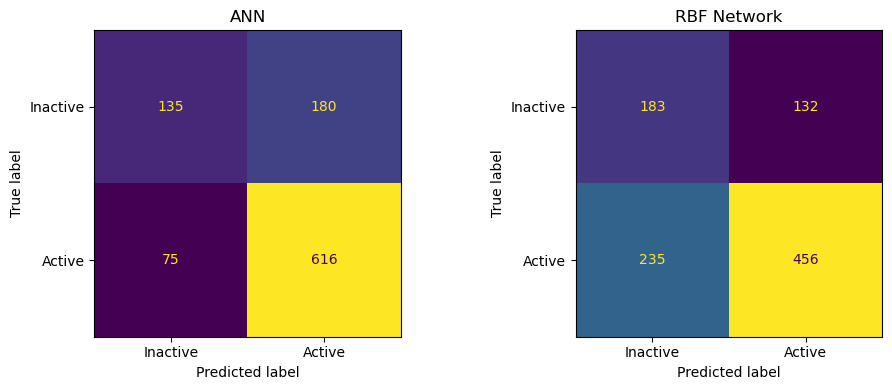

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, pred in zip(axes, ["ANN", "RBF Network"], [ann_pred, rbf_pred]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Inactive", "Active"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [25]:
xgb=XGBClassifier(max_depth=8,n_estimators=300,gamma=0.1,random_state=42)
xgb.fit(X_train,y_train)
xgb_pred=xgb.predict(X_test)
xgb_prob=xgb.predict_proba(X_test)[:,1]

In [26]:
xgb_pred=xgb.predict(X_test)
xgb_prob=xgb.predict_proba(X_test)[:,1]
print(xgb_pred)

[0 0 1 ... 1 0 1]


In [27]:
import numpy as np
from rdkit.Chem import rdFingerprintGenerator
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fingerprints = []
valid_targets = []
for smiles, target in zip(df["smiles"], df["target"]):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        fp = fp_gen.GetFingerprint(mol)
        arr = np.zeros((1,))
        Chem.DataStructs.ConvertToNumpyArray(fp, arr)
        fingerprints.append(arr)
        valid_targets.append(target)
X_fp = np.array(fingerprints)
y_fp = np.array(valid_targets)
X_train_fp, X_test_fp, y_train_fp, y_test_fp = train_test_split(X_fp, y_fp, test_size=0.2, random_state=42, stratify=y_fp)
xgb_improved = XGBClassifier(max_depth=6, n_estimators=400, learning_rate=0.05, random_state=42)
xgb_improved.fit(X_train_fp, y_train_fp)
y_pred_fp = xgb_improved.predict(X_test_fp)
y_prob_fp = xgb_improved.predict_proba(X_test_fp)[:, 1]
new_acc = accuracy_score(y_test_fp, y_pred_fp)
new_prec = precision_score(y_test_fp, y_pred_fp)
new_rec = recall_score(y_test_fp, y_pred_fp)
new_f1 = f1_score(y_test_fp, y_pred_fp)
new_roc = roc_auc_score(y_test_fp, y_prob_fp)

print(f"XGBoost:")
print(f"Accuracy:  {new_acc:.4f}")
print(f"Precision: {new_prec:.4f}")
print(f"Recall:    {new_rec:.4f}")
print(f"F1 Score:  {new_f1:.4f}")
print(f"ROC-AUC:   {new_roc:.4f}")

XGBoost:
Accuracy:  0.8002
Precision: 0.8047
Recall:    0.9363
F1 Score:  0.8656
ROC-AUC:   0.8450


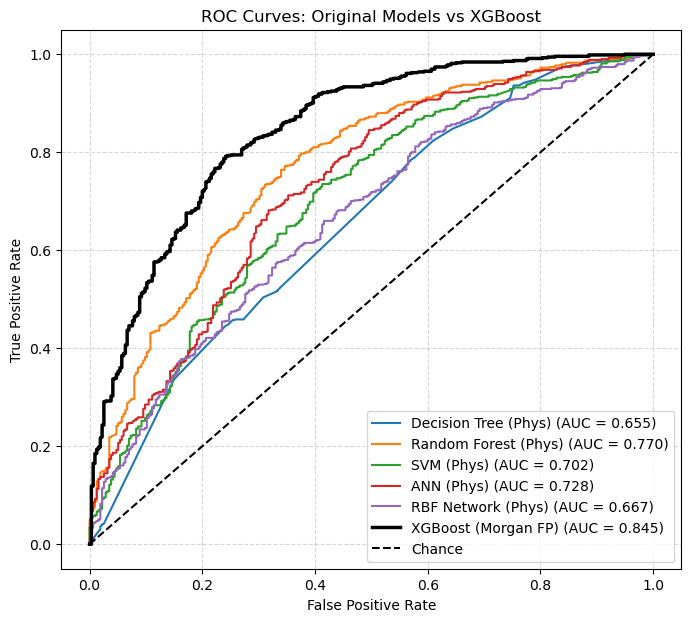

In [28]:
plt.figure(figsize=(8, 7))
models_to_plot = [
    ("Decision Tree (Phys)", tree_prob, y_test),
    ("Random Forest (Phys)", forest_prob, y_test),
    ("SVM (Phys)", svm_prob, y_test),
    ("ANN (Phys)", ann_prob, y_test),
    ("RBF Network (Phys)", rbf_prob, y_test)
]
for name, prob, y_true in models_to_plot:
    fpr_orig, tpr_orig, _ = roc_curve(y_true, prob)
    auc_val = roc_auc_score(y_true, prob)
    plt.plot(fpr_orig, tpr_orig, label=f"{name} (AUC = {auc_val:.3f})")
fpr_fp, tpr_fp, _ = roc_curve(y_test_fp, y_prob_fp)
plt.plot(fpr_fp, tpr_fp, label=f"XGBoost (Morgan FP) (AUC = {new_roc:.3f})", linewidth=2.5, color='black')
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Original Models vs XGBoost")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

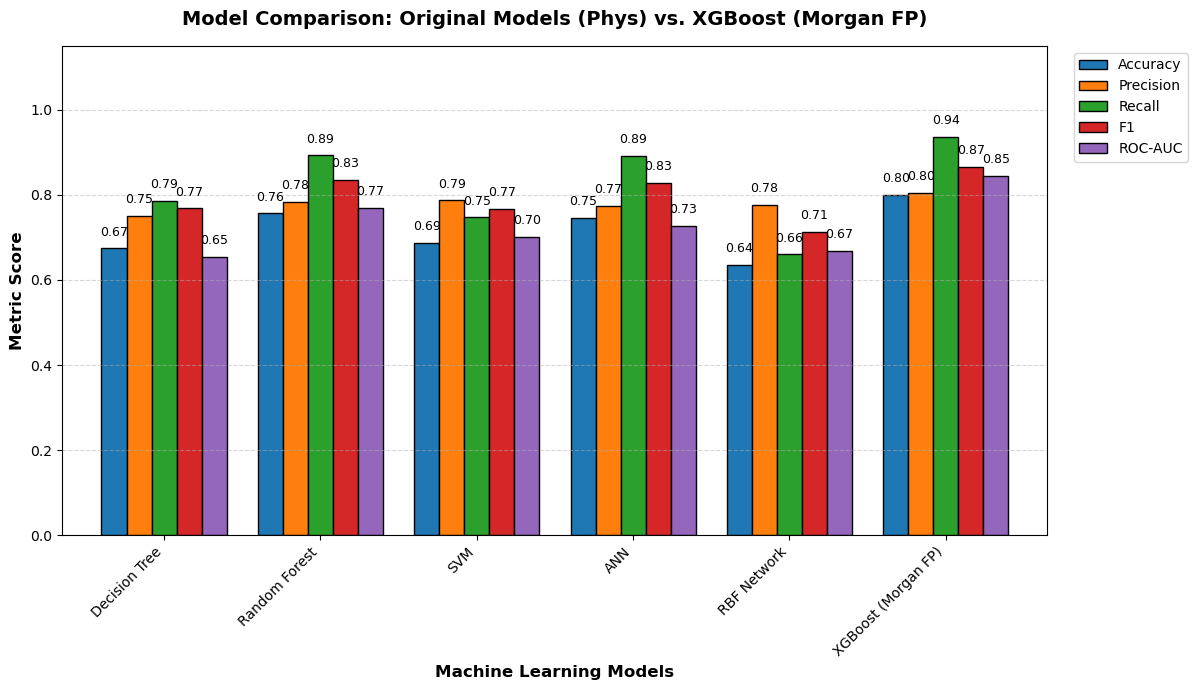

In [29]:
comparison_df = extended_results.copy()
comparison_df["XGBoost (Morgan FP)"] = [new_acc, new_prec, new_rec, new_f1, new_roc]
plot_df=comparison_df.T
plot_df.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
ax = plot_df.plot(kind="bar", figsize=(12, 7), width=0.8, edgecolor="black")
plt.title("Model Comparison: Original Models (Phys) vs. XGBoost (Morgan FP)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Machine Learning Models", fontsize=12, fontweight='bold')
plt.ylabel("Metric Score", fontsize=12, fontweight='bold')
plt.ylim(0, 1.15)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(loc="upper right", bbox_to_anchor=(1.15, 1.0))
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=7, fontsize=9)
plt.tight_layout()
plt.show()

In [30]:
# Model Comparison Table - Including XGBoost

import pandas as pd

# Use comparison_df because it contains the XGBoost (Morgan FP) model
comparison_table = comparison_df.T

# Rename metric columns
comparison_table.columns = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

# Convert scores into percentages
comparison_table = (comparison_table * 100).round(2)

# Sort models by F1-Score
comparison_table = comparison_table.sort_values(
    by="F1-Score",
    ascending=False
)

# Display table
print("BIOACTIVE MOLECULE PREDICTION - MODEL COMPARISON")
display(comparison_table)

BIOACTIVE MOLECULE PREDICTION - MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
XGBoost (Morgan FP),80.02,80.47,93.63,86.56,84.50
Random Forest,75.65,78.30,89.29,83.43,76.97
ANN,74.65,77.39,89.15,82.85,72.77
Decision Tree,67.40,75.10,78.58,76.80,65.46
SVM,68.69,78.66,74.67,76.61,70.19
RBF Network,63.52,77.55,65.99,71.31,66.75


In [41]:
xgb_improved.save_model("xgb_cox2_model.json")

In [31]:
import os

print("Current folder:", os.getcwd())
print("Model exists:", os.path.exists("xgb_cox2_model.json"))

Current folder: /Users/m.saikarthikeya/Desktop/XGBioactiveNew/notebooks
Model exists: True


In [35]:
from pathlib import Path

model_path = Path("xgb_cox2_model.json").resolve()
print(model_path)

/Users/m.saikarthikeya/Desktop/XGBioactiveNew/notebooks/xgb_cox2_model.json


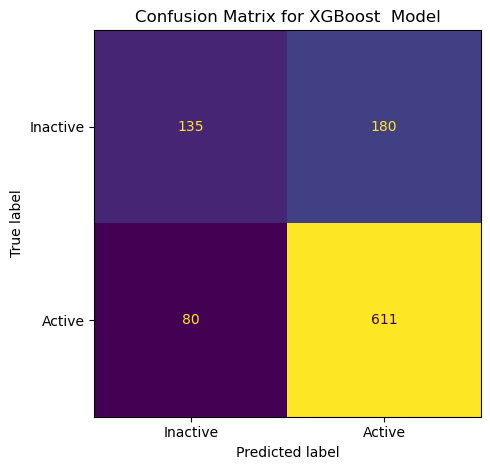

In [36]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, xgb_pred)
ConfusionMatrixDisplay(cm, display_labels=["Inactive", "Active"]).plot(colorbar=False)
plt.title("Confusion Matrix for XGBoost  Model")   
plt.tight_layout()
plt.show() 
